# Titania ellipsometry: active reconstruction and scientific review

This notebook actively infers the TiO2 refractive-index dispersion and thickness from **926 real measured spectral points at one acquisition angle**. It uses the original author-selected transparent400–800nm window without dropping any selected point. The stack is air / TiO2 / SiO2 / silicon. The supplied Si substrate index and SiO2 calibration are fixed, not new fitted unknowns. No actual TiO2 truth is available; original-source fits are method references.

The reported incidence is **70.06degrees**, while the published example evaluates its selected model at **70degrees**. We reproduce that explicit70degree method and separately measure the effect of the difference. Source2x2 and source4x4 runs, the initial model and fresh local fits are identified separately. The six chapters show acquisition, physical fitting, residuals, material properties/conditioning, actual alternate-start fits and physical/angle sensitivity.

## 1. Measured polarization spectra

Ellipsometry measures the relative amplitude and phase of reflected p and s polarization. With the supplied phase convention, the complex reflection ratio is

$$\rho=\tan(\Psi)\exp(-i\Delta)=r_p/r_s.$$

Here $\Psi$ and $\Delta$ are measured angles in degrees before conversion to radians inside the exponential. The negative phase sign is part of the acquisition convention. The signed phase is circular; a jump near180degrees is a representation boundary, not an intensity discontinuity.

Active scientific kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
All selected wavelengths [nm]: 400.07646 799.71891


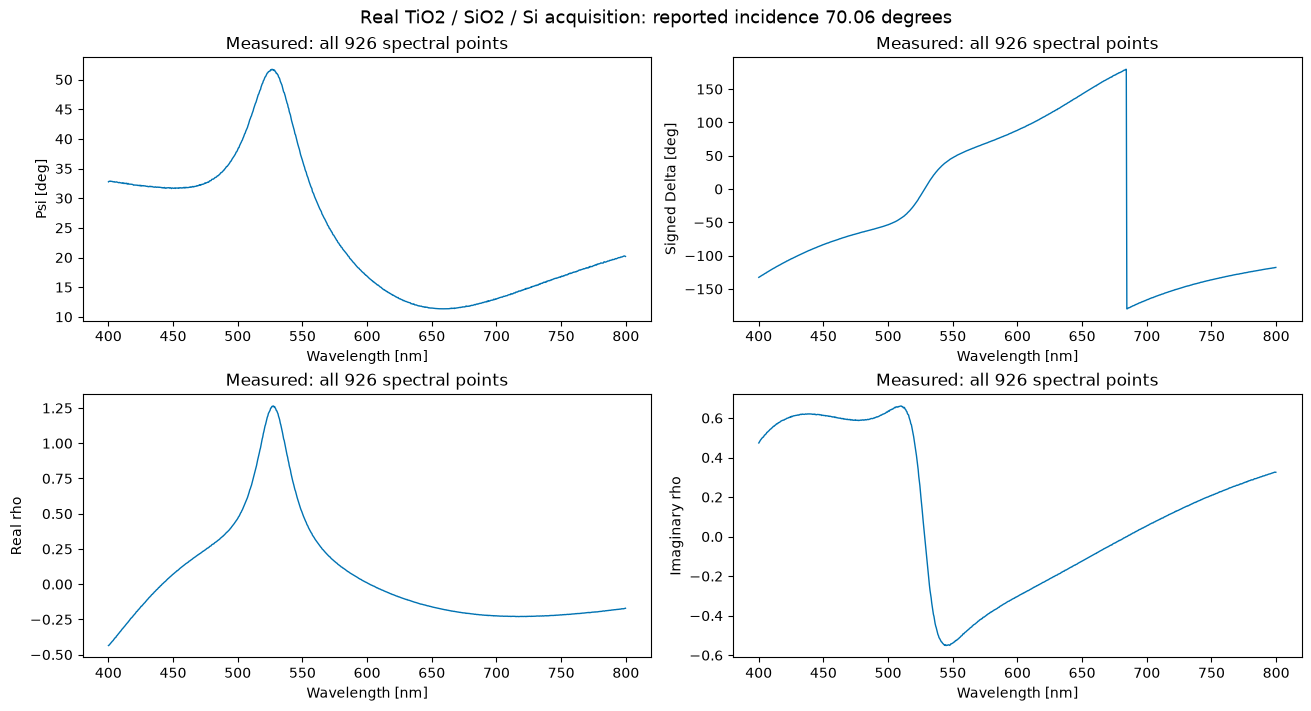

In [1]:
%matplotlib inline
from pathlib import Path
import sys,os,time,json,tempfile,hashlib,subprocess
for variable in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'): os.environ[variable]='1'
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import predict_rho,cauchy_index,reflection
from src.solvers import reconstruct
from src.main import run
from src import visualization as viz
data=load_observations(ROOT/'data/raw_data.npz')
assert data['wavelength_nm'].shape==(926,)
with np.load(ROOT/'notebooks/reference_outputs/upstream_fit.npz',allow_pickle=False) as archive:
    source={key:archive[key].copy() for key in archive.files}
with np.load(ROOT/'notebooks/reference_outputs/upstream_4x4_fit.npz',allow_pickle=False) as archive:
    source4x4={key:archive[key].copy() for key in archive.files}
assert np.array_equal(data['wavelength_nm'],source['wavelength_nm'])
assert np.allclose(viz.observed_rho(data),source['rho_observed'],rtol=0,atol=1e-14)
FIGURES=Path(os.environ.get('IMAGING101_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging101_review/titania_ellipsometric_dispersion_thickness')))
raw_sha256=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
provenance=dict(raw_data_sha256=raw_sha256,source_commit='4a8787654477355167df74bbf0b6003e8fc35a4d',data_type='real',points=926,reported_angle_deg=70.06,selected_source_model_angle_deg=70.,reference_type='Independently executed original method; no actual material truth',kernel_executable=sys.executable)
def show_export(fig,arrays,name,extra=None):
    viz.export_figure(fig,FIGURES/name,arrays,dict(**provenance,**(extra or {})))
    display(fig);plt.close(fig)
print('Active scientific kernel:',sys.executable)
print('All selected wavelengths [nm]:',float(data['wavelength_nm'].min()),float(data['wavelength_nm'].max()))
fig,arrays=viz.acquisition_figure(data)
show_export(fig,arrays,'01_real_acquisition')

## 2. Layer physics, initial model and complete fresh fit

The unknown parameter vector is $p=(n_0,n_1,n_2,d)$, where$d$ is TiO2 thickness in nm. The transparent-film Cauchy law in the source's scaled numerical convention is

$$n(\lambda)=n_0+100n_1/\lambda^2+10^7n_2/\lambda^4,\qquad k=0,$$

where$\lambda$ is in nm and$k$ is the extinction coefficient. The fixed oxide has$n=1.452+3600/\lambda^2$, thickness276.36nm and zero absorption. The substrate index is complex and wavelength dependent.

For each layer, $q_j=\sqrt{n_j^2-\sin^2\theta}$ is the normal wavevector factor, with the passive branch selected. Fresnel interface coefficients, propagation phase$\beta_j=2\pi q_jd_j/\lambda$ and ordered interface/propagation matrix products generate$r_s$ and$r_p$. The local implementation explicitly evaluates these operations. The inverse minimizes the unweighted sum of squared real and imaginary parts of$\rho_{\rm model}-\rho_{\rm measured}$, using the selected source initialization and bounds described in the plans. Neither displayed phase residuals nor their units replace that complex objective.

The author gallery plots the initial and final models. We preserve that comparison: the initial source parameter vector$(2.236,451,251,20)$ is actively folded through the local physical model, while final original2x2 and original4x4 fits are frozen independent measurements. **The main result below is freshly optimized**, not read from either reference. The initial curve is labeled as local forward evaluation rather than falsely called an archived source curve.

Actual fit seconds: 0.027572099992539734
Fresh fit status: {'success': True, 'message': 'The relative error between two consecutive iterates is at most 0.000000', 'nfev': 32, 'seconds': 0.026077500020619482}
Parameter order [n0,n1,n2,d_nm]: [  2.22973557 461.68933963 189.77957481  24.84463962]
Original 2x2 parameters: [  2.22973557 461.68934019 189.77957412  24.84463962]
Original 4x4 parameters: [  2.22973557 461.68933974 189.77957469  24.84463962]


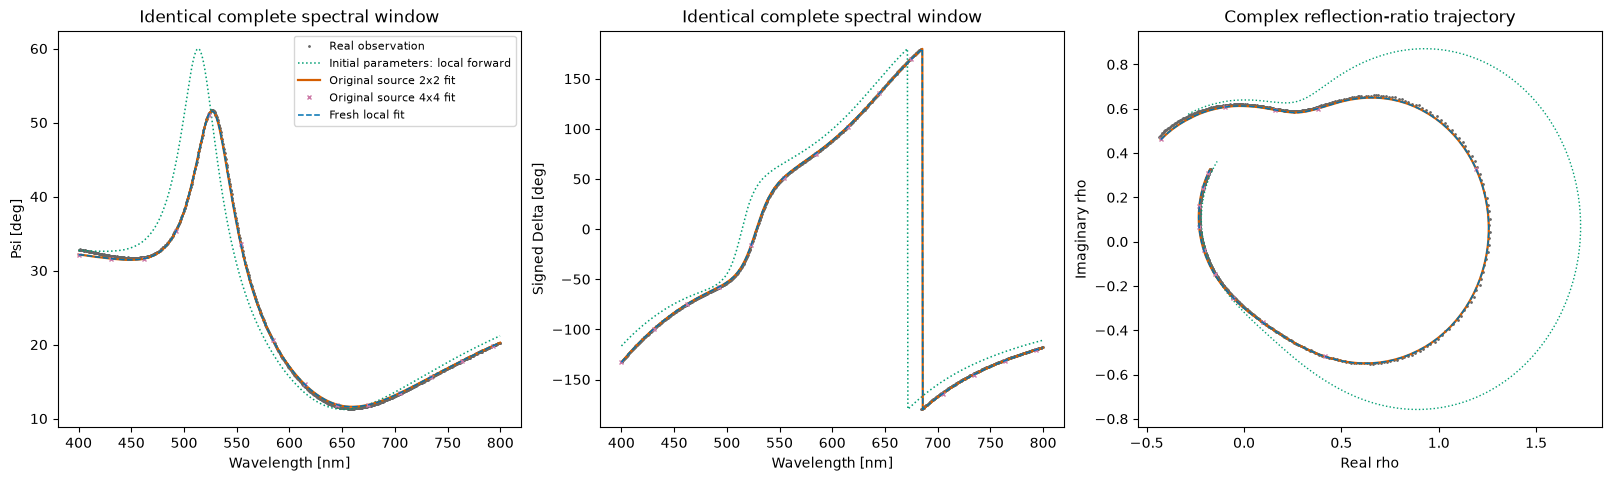

In [2]:
initial=np.asarray([2.236,451.,251.,20.],dtype=np.float64)
initial_rho=predict_rho(data,initial,angle_deg=70.)
started=time.perf_counter()
fresh_output,fresh_record=run(data_path=ROOT/'data/raw_data.npz',output_path=ROOT/'output/reconstruction.npz')
active_fit_seconds=time.perf_counter()-started
parameters=np.asarray(fresh_output['parameters']).reshape(4)
fresh_rho=predict_rho(data,parameters,angle_deg=70.)
print('Actual fit seconds:',active_fit_seconds)
print('Fresh fit status:',{key:fresh_record.get(key) for key in ('success','message','nfev','seconds')})
print('Parameter order [n0,n1,n2,d_nm]:',parameters)
print('Original 2x2 parameters:',source['parameters'])
print('Original 4x4 parameters:',source4x4['parameters'])
fig,arrays=viz.spectrum_figure(data,fresh_rho,source,initial_rho,source4x4)
show_export(fig,arrays,'02_initial_original_fresh_spectra',dict(active_fit_seconds=active_fit_seconds,initial_parameters=initial.tolist(),fresh_parameters=parameters.tolist(),original2x2_parameters=source['parameters'].tolist(),original4x4_parameters=source4x4['parameters'].tolist()))

## 3. Fit residuals and independent evaluation

All926 points enter every residual. The objective uses complex$\rho$ directly. For interpretation, the polarization residuals are$\hat\Psi-\Psi$ and$\operatorname{wrap}_{[-180,180)}(\hat\Delta-\Delta)$. The relative complex-ratio RMS is$\|\hat\rho-\rho\|_2/\|\rho\|_2$. The phase wrapping is only the scientifically defined circular comparison, not an image/parameter alignment.

The source qualification measured relative$\rho$ RMS0.0122210, $\Psi$ RMS0.226052degree and circular$\Delta$ RMS0.693228degree. These real-data residuals are not zero and are not independent truth errors. The standalone Judge evaluates every declared physical output and its frozen boundaries, including physical scale. The source and fresh curves below use the same observations and formulas.

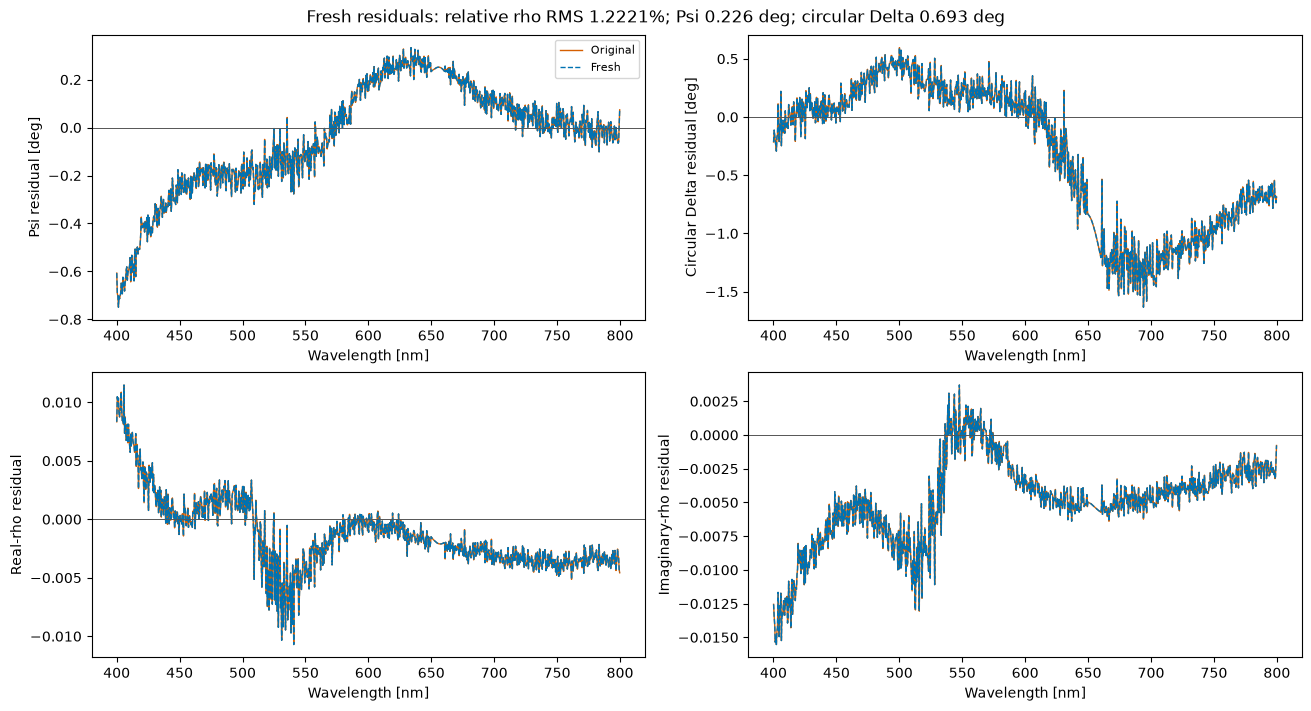

Fresh observation diagnostics: {
  "relative_complex_rho_rms": 0.012221012668514107,
  "psi_rms_deg": 0.22605185267059896,
  "circular_delta_rms_deg": 0.6932280901902916
}
Original 2x2 observation diagnostics: {
  "relative_complex_rho_rms": 0.012221012668514077,
  "psi_rms_deg": 0.22605185269613398,
  "circular_delta_rms_deg": 0.6932280901499218
}
Original 4x4 observation diagnostics: {
  "relative_complex_rho_rms": 0.012221012668515248,
  "psi_rms_deg": 0.22605185267292568,
  "circular_delta_rms_deg": 0.693228090139951
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "n0_absolute_error": 1.1479528438940179e-10,
    "n1_absolute_error": 5.64898073207587e-07,
    "n2_absolute_error": 6.959890015423298e-07,
    "thickness_nm_absolute_error": 5.995204332975845e-11,
    "nrmse": 7.824234601073549e-11,
    "index_consistency_absolute_error": 0.0,
    "rho_relative_rms": 0.012221012668514294
  },
  "thresholds": {
    "n0_absolute_error": {
      "comparison": "<=",
      "bound

In [3]:
fig,arrays,fresh_metrics=viz.residual_figure(data,fresh_rho,source['rho_fitted'])
show_export(fig,arrays,'03_full_spectral_residuals',dict(fresh_metrics=fresh_metrics))
print('Fresh observation diagnostics:',json.dumps(fresh_metrics,indent=2))
print('Original 2x2 observation diagnostics:',json.dumps(viz.comparison_metrics(data,source['rho_fitted']),indent=2))
print('Original 4x4 observation diagnostics:',json.dumps(viz.comparison_metrics(data,source4x4['rho_fitted']),indent=2))
judge=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert judge.returncode==0,(judge.returncode,judge.stderr)
judge_report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf-8'))
print(json.dumps(judge_report,indent=2))

## 4. Material dispersion, thickness and conditional identifiability

We display the actual reconstructed TiO2$n(\lambda)$ and thickness in physical units. There is no fitted output rescaling. Numerical parity with an original fit is distinct from uncertainty in the actual material.

For the1852-component real/imaginary prediction vector, a centered finite difference estimates the Jacobian. Columns are multiplied by$\max(|p_j|,1)$ so the condition number is not dominated by raw coefficient units. The original independent diagnostic had rank4 and condition2713.34. Full local rank means the selected finite model has four numerically distinguishable directions; the large condition number and source conditional coefficient correlations still warn against treating all reported digits as physical precision.

The correlation matrix below is from the original source's actual conditional fit covariance. It is not a new uncertainty estimate for fresh fits or a guarantee of calibrated confidence; it conditions on this stack, model, objective and residual assumptions.

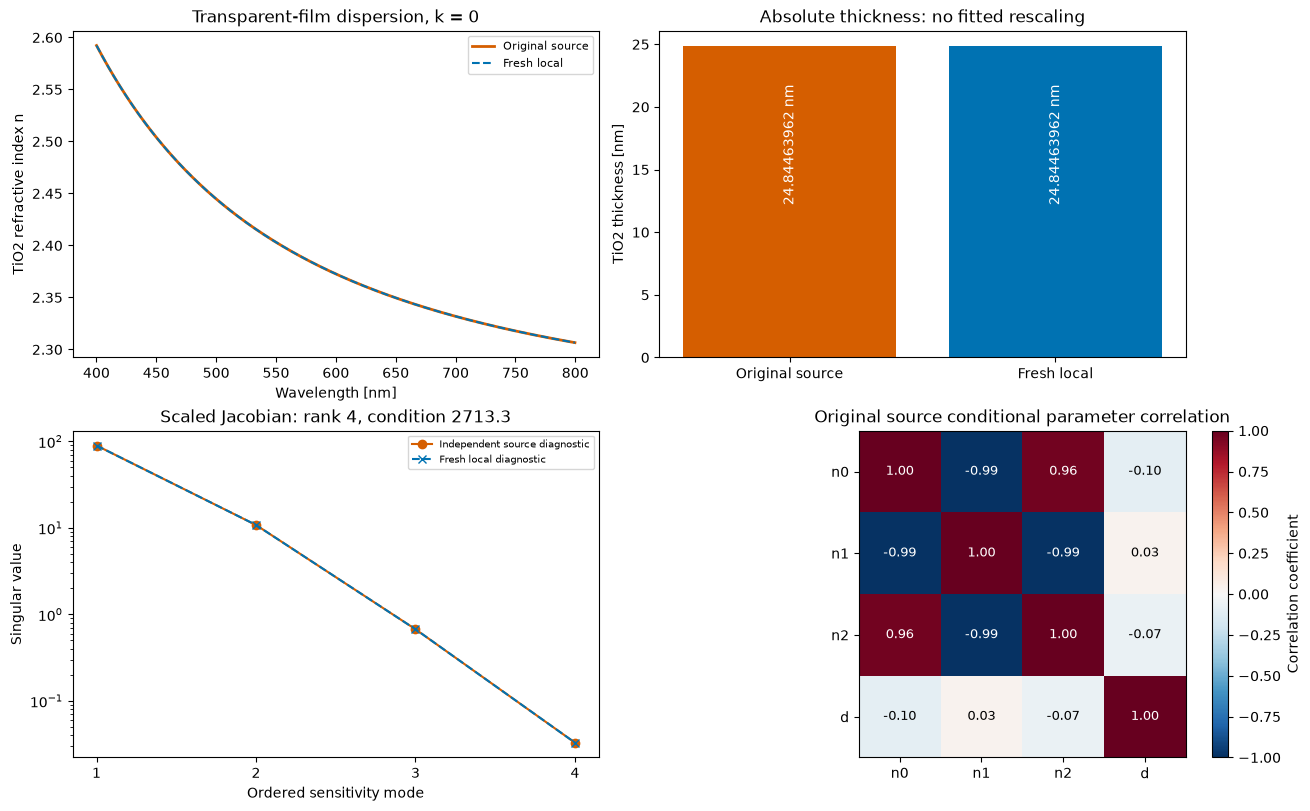

Fresh scaled Jacobian rank: 4
Fresh scaled condition: 2713.3445321194095
Source conditional coefficient standard errors: [4.72756198e-03 2.21724774e+01 2.57876507e+01 1.01389356e-02]


In [4]:
fig,arrays=viz.properties_figure(data,parameters,source['parameters'],source['covariance'],source['source_singular_values'])
show_export(fig,arrays,'04_dispersion_thickness_conditioning',dict(uncertainty='Original-source conditional covariance only; not absolute physical uncertainty'))
singular=arrays['fresh_singular_values']
print('Fresh scaled Jacobian rank:',int(np.linalg.matrix_rank(arrays['fresh_scaled_jacobian'])))
print('Fresh scaled condition:',float(singular[0]/singular[-1]))
print('Source conditional coefficient standard errors:',np.sqrt(np.diag(source['covariance'])))

## 5. Actually computed alternate initializations

We now run three additional local fits from explicitly shown initial parameter vectors, using the same926 observations,70degree model, bounds and objective. The standard fit remains the benchmark output. These supplementary measurements test optimization stability; they do not add acquisition angles or substitute an easier inverse problem.

The panels show the initial/final thickness pairs, actual final objective values, every resulting$n(\lambda)$ curve and reported function-evaluation counts. Function evaluations, including finite-difference calls, are **not optimizer iterations**. No absent fit is filled with a reference or a zero curve. Any failed convergence is printed explicitly and remains distinguishable from the standard fit.

Start A initial [2.1, 300.0, 100.0, 15.0] fresh fitted [2.2297400000034457, 461.6673554352965, 189.8046462370039, 24.844644552464157] status {'success': True, 'message': 'The relative error between two consecutive iterates is at most 0.000000', 'nfev': 147, 'seconds': 0.26770580001175404}
Start B initial [2.5, 600.0, 350.0, 35.0] fresh fitted [2.2297346325830745, 461.69433711189777, 189.77336710687086, 24.84463668853243] status {'success': True, 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000 and the relative error between two consecutive iterates is at \n  most 0.000000', 'nfev': 36, 'seconds': 0.06292950001079589}
Start C initial [2.3, 500.0, 150.0, 50.0] fresh fitted [2.229734613220387, 461.6944383774171, 189.77324733718706, 24.844636637135764] status {'success': True, 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000 and the relative error between two consecutive iterates i

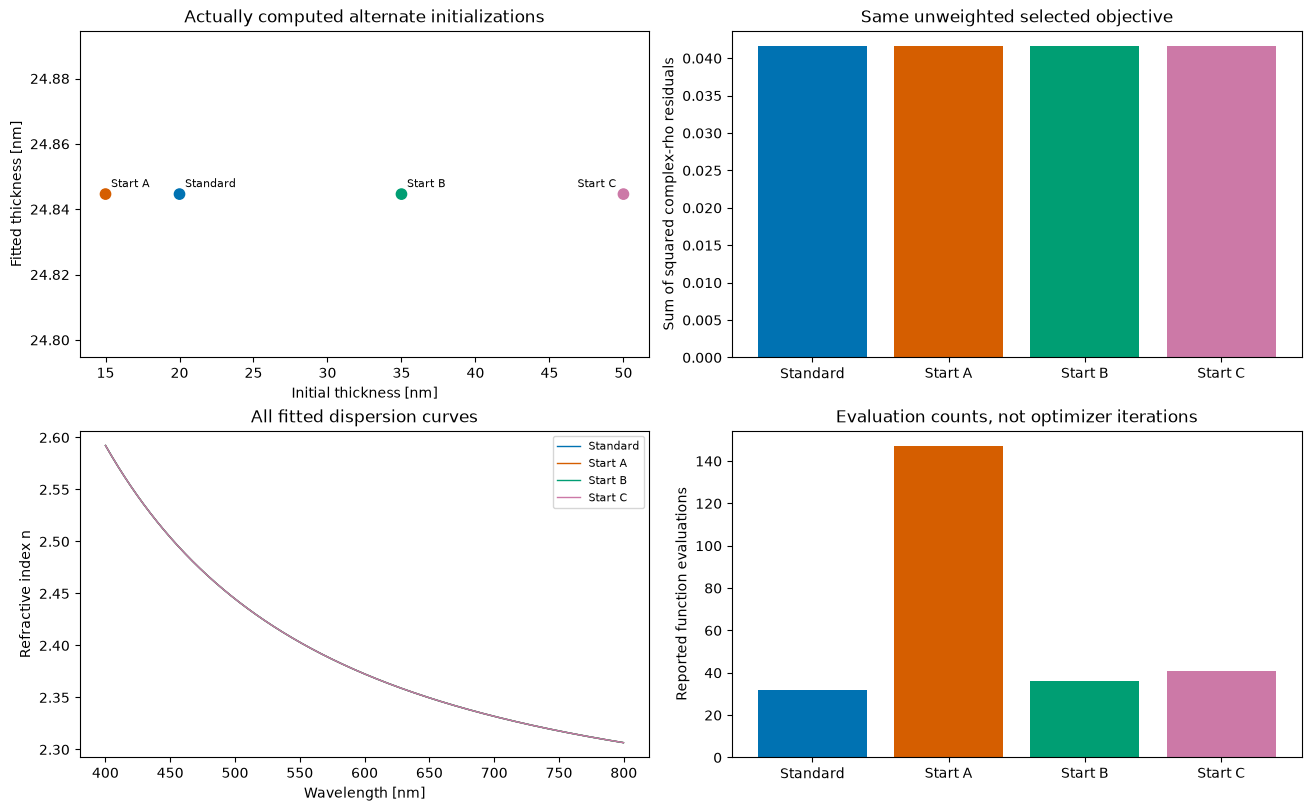

Actual final objective values: [0.041605770387414004, 0.04160576846971807, 0.0416057712957327, 0.0416057713122769]


In [5]:
starts=[initial,np.asarray([2.1,300.,100.,15.]),np.asarray([2.5,600.,350.,35.]),np.asarray([2.3,500.,150.,50.])]
labels=['Standard','Start A','Start B','Start C']
solutions=[parameters.copy()];records=[fresh_record]
for start,label in zip(starts[1:],labels[1:]):
    result,record=reconstruct(data,initial=start)
    solutions.append(np.asarray(result['parameters']).reshape(4).copy());records.append(record)
    print(label,'initial',start.tolist(),'fresh fitted',solutions[-1].tolist(),'status',{key:record.get(key) for key in ('success','message','nfev','seconds')})
objectives=[]
for parameter in solutions:
    residual=predict_rho(data,parameter)-viz.observed_rho(data)
    objectives.append(float(np.sum(residual.real**2+residual.imag**2)))
evaluation_counts=[int(record['nfev']) for record in records]
fig,arrays=viz.multistart_figure(data,starts,solutions,labels,objectives,evaluation_counts)
show_export(fig,arrays,'05_actual_multistart_fits',dict(convergence_success=[bool(record['success']) for record in records],objective='Sum squared complex-rho residual; same complete926 observations'))
print('Actual final objective values:',objectives)

## 6. Incidence discrepancy, passive optics and conclusion

The recorded70.06degree angle and the selected source-model70degree angle are distinct known quantities. Holding the fitted parameters fixed, we explicitly recompute the forward prediction at nearby angles; this is a **model sensitivity calculation**, not newly measured multi-angle data, not a refit and not a change to the benchmark method. The source qualification found that using the same fitted parameters at70.06degrees increased relative$\rho$ RMS from0.0122210 to0.0136598. That discrepancy must remain visible rather than silently changing the model to improve a score.

The reflectance panels show the freshly calculated$|r_s|^2$ and$|r_p|^2$; a passive stack must remain within[0,1]. Independent zero-thickness/interface and source2x2/4x4 tests are covered by the maintainer test suite. The last panel isolates fresh-vs-original complex-ratio differences at the selected70degree model.

This review establishes a complete reproducible local implementation of the selected layered-optics inverse, preserves the original initial/final comparison and compares independently measured source backends. It does not establish absolute TiO2 truth: single-angle inference depends on fixed substrate/oxide calibration, a transparent Cauchy model, incidence convention, coefficient correlation and the observed structured residuals.

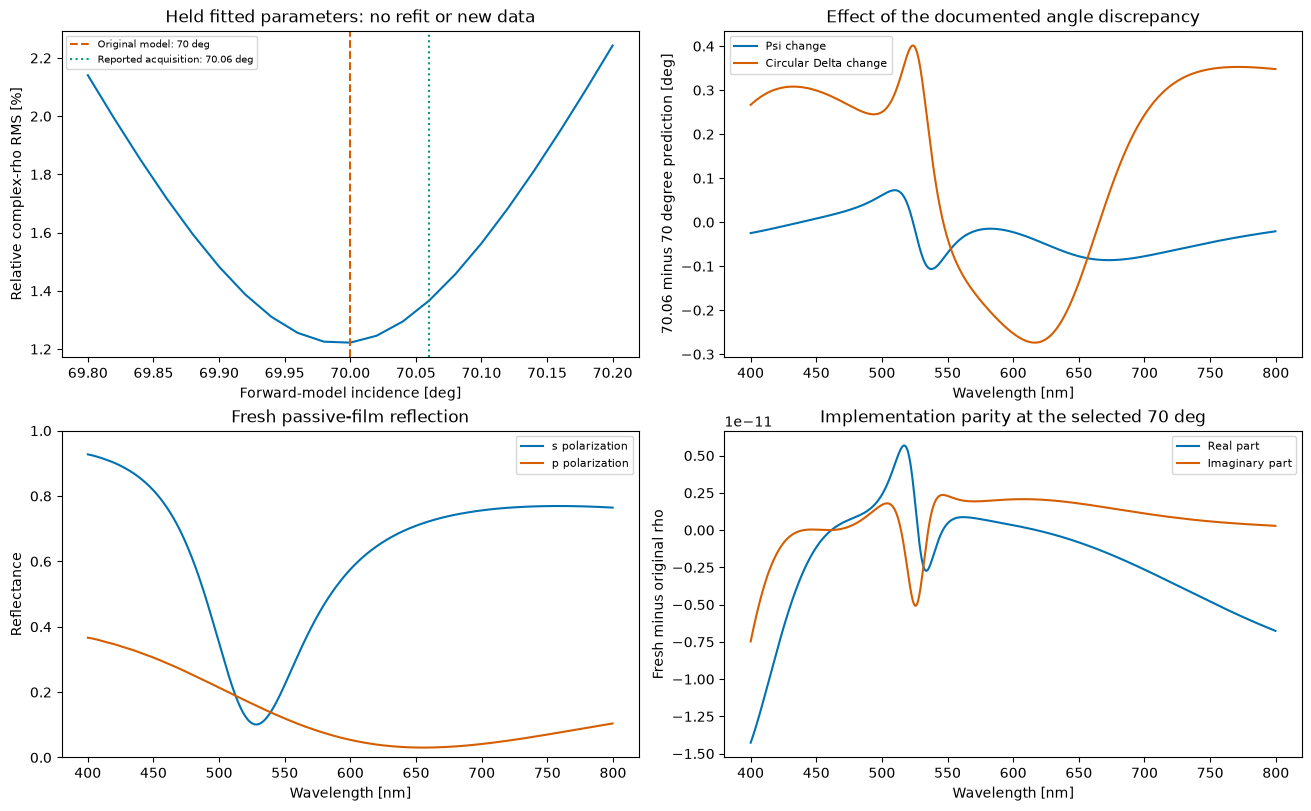

Selected70degree model: {
  "relative_complex_rho_rms": 0.012221012668514107,
  "psi_rms_deg": 0.22605185267059896,
  "circular_delta_rms_deg": 0.6932280901902916
}
Same parameters at recorded70.06degree angle: {
  "relative_complex_rho_rms": 0.013659754824417484,
  "psi_rms_deg": 0.21426759334192522,
  "circular_delta_rms_deg": 0.6453926986832373
}
Original-source backend rho relative difference: 7.29265811403757e-12
Fresh-source rho relative difference: 8.081904130805608e-12
Scientific review complete: 926 real measured points; 4 actual local fits; six exported figures in D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\groups\root\material_candidate_astro\figures


In [6]:
angles=np.unique(np.r_[np.linspace(69.8,70.2,21),70.06])
fig,arrays=viz.sensitivity_figure(data,parameters,angles,source['rho_fitted'])
show_export(fig,arrays,'06_angle_sensitivity_and_physics',dict(parameters_held_fixed=True,refit=False,extra_acquisition_data=False))
assert np.all((arrays['reflectance_s']>=0)&(arrays['reflectance_s']<=1))
assert np.all((arrays['reflectance_p']>=0)&(arrays['reflectance_p']<=1))
print('Selected70degree model:',json.dumps(viz.comparison_metrics(data,arrays['rho_at_model_angle']),indent=2))
print('Same parameters at recorded70.06degree angle:',json.dumps(viz.comparison_metrics(data,arrays['rho_at_reported_angle']),indent=2))
print('Original-source backend rho relative difference:',float(np.linalg.norm(source4x4['rho_fitted']-source['rho_fitted'])/np.linalg.norm(source['rho_fitted'])))
print('Fresh-source rho relative difference:',float(np.linalg.norm(fresh_rho-source['rho_fitted'])/np.linalg.norm(source['rho_fitted'])))
measurements=dict(parameters=parameters,reconstruction=fresh_output['reconstruction'],rho_fresh=fresh_rho,rho_initial=initial_rho,
                  fresh_covariance=fresh_record['covariance'],multistart_initials=np.asarray(starts),multistart_parameters=np.asarray(solutions),
                  multistart_objectives=np.asarray(objectives),multistart_function_evaluations=np.asarray(evaluation_counts),
                  fresh_scaled_singular_values=singular,rho_at_reported_angle=arrays['rho_at_reported_angle'])
for index,record in enumerate(records):measurements[f'fit_{index}_evaluation_trace']=record['evaluations']
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',**measurements)
fresh_summary=dict(**provenance,active_fit_seconds=active_fit_seconds,standard_nfev=int(fresh_record['nfev']),fresh_metrics=fresh_metrics,
                   fresh_parameters=parameters.tolist(),source_parameter_absolute_difference=abs(parameters-source['parameters']).tolist(),
                   actual_multistart_objectives=objectives,actual_multistart_nfev=evaluation_counts,
                   actual_multistart_success=[bool(record['success']) for record in records],fresh_scaled_condition=float(singular[0]/singular[-1]),
                   canonical_main_output='output/reconstruction.npz',source_fit_used_as_truth=False)
(ROOT/'notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps(fresh_summary,indent=2,allow_nan=False),encoding='utf-8')
print('Scientific review complete:',len(data['wavelength_nm']),'real measured points;',len(solutions),'actual local fits; six exported figures in',FIGURES)